# IMPORT

In [26]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import folium
import csv
import json
import os

# DEFINE FOLDERS

In [27]:
BASE_FOLDER = Path("../data")
JSON_INPUT_FOLDER = BASE_FOLDER / "00_raw" / "json" / "correlated_data_json"
DATASET_INPUT_FOLDER = BASE_FOLDER / "00_raw" / "csv" / "correlated_data_csv"
DATASET_OUTPUT_FOLDER = BASE_FOLDER / "01_clean" / "datasets"
DELETED_STATIONS_FOLDER = BASE_FOLDER / "01_clean" / "deleted_stations"
MAP_FOLDER = BASE_FOLDER / "05_visualization" / "maps"
COORDINATES_FOLDER = BASE_FOLDER / "02_features" / "station_coordinates"
PIPELINE_STATS_FOLDER = BASE_FOLDER / "06_statistics" / "pipeline"

folders = [JSON_INPUT_FOLDER, DATASET_INPUT_FOLDER, DATASET_OUTPUT_FOLDER, DELETED_STATIONS_FOLDER, MAP_FOLDER, COORDINATES_FOLDER, PIPELINE_STATS_FOLDER]
for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

# DEFINE CONSTANTS

In [28]:
REMAKE_CSV = False # To get the dataset from json files(will be saved in a csv file)
CSV_FILE_NAME = "correlated_data" #To save the dataset from json to csv/to get the dataset from csv
FINAL_CSV_FILE_NAME = "final_clean_split_data" # The prepared dataset

# DEFINE VARIABLES

In [29]:
# Not exactly variables as we will modify them only once at the start
TOTAL_ROWS_AT_START = 1 # 1 to avoid division by zero
TOTAL_REAL_ROWS_AT_START = 1
TOTAL_STATIONS_AT_START = 1
TOTAL_REAL_STATIONS_AT_START = 1
pipeline_stats = [] 

# DEFINE FUNCS

In [30]:
def log_pipeline_step(df, step_name):
    station_col = "station_code" if "station_code" in df.columns else "stationcode" 
    pipeline_stats.append({ 
        "step": step_name, 
        "rows": df.shape[0], 
        "stations": df[station_col].nunique() 
        })

def print_df(dataframe):
    print("=========================================")
    print(f"Dataframe analysis")
    print("-----------------------")
    print(f"Shape: \nrows:     {dataframe.shape[0]}\nfeatures: {dataframe.shape[1]}")
    
    # Size of the dataframe it takes in RAM
    data_size_bytes = dataframe.memory_usage(deep=True).sum()
    data_size_mb = data_size_bytes / (1024**2)
    print(f"Dataframe size: {data_size_bytes} bytes ({data_size_mb:.2f} MB)")

    print("-----------------------")

    # We do this because at one point we change the column's name
    station_col = "station_code" if "station_code" in dataframe.columns else "stationcode"

    rows_pct = (TOTAL_ROWS_AT_START - dataframe.shape[0]) / TOTAL_ROWS_AT_START * 100
    stations_pct = (TOTAL_STATIONS_AT_START - dataframe[station_col].nunique()) / TOTAL_STATIONS_AT_START * 100
    real_rows_pct = (TOTAL_REAL_ROWS_AT_START - dataframe.shape[0]) / TOTAL_REAL_ROWS_AT_START * 100
    real_stations_pct = (TOTAL_REAL_STATIONS_AT_START - dataframe[station_col].nunique()) / TOTAL_REAL_STATIONS_AT_START * 100

    print(f"Percentage of rows removed: {rows_pct:.2f}%")
    print(f"Percentage of stations removed: {stations_pct:.2f}%")
    print(f"Percentage of real rows removed: {real_rows_pct:.2f}%")
    print(f"Percentage of real stations removed: {real_stations_pct:.2f}%")

    print("-----------------------")
    # To see what columns we have as what data type
    display(dataframe.dtypes)
    print("-----------------------")
    # Basic statistics
    display(dataframe.describe())
    print("=========================================")

MISSING_STRINGS = {"", "na", "n/a", "null", "none", "nan", "-"}
def rows_with_missing(df):
    # NaN anywhere
    mask = df.isna().any(axis=1)

    # Only object columns
    obj_df = df.select_dtypes(include="object")

    if not obj_df.empty:
        # Normalize all strings
        normalized = obj_df.apply(
            lambda col: col.str.strip().str.lower()
        )

        # Check missing-like strings (row-wise)
        string_missing = normalized.isin(MISSING_STRINGS).any(axis=1)

        # Add missing strings to mask
        mask |= string_missing

    return df[mask]

def print_missing(dataframe, max_rows=10):
    print("=========================================")
    print(f"Missing diagnostics")
    print("-----------------------")

    # NaN count per column
    nan_counts = dataframe.isna().sum().sort_values(ascending=False)

    # Inf count per numeric column
    numeric_df = dataframe.select_dtypes(include=[np.number])
    inf_counts = np.isinf(numeric_df).sum()

    problem_counts = (
        pd.DataFrame({
            "nan": nan_counts,
            "inf": inf_counts
        })
        .fillna(0)
        .astype(int)
        .sort_values(by=["nan", "inf"], ascending=False)
    )

    print("\nNaN / Inf per column:")
    display(problem_counts)

    print("-----------------------")

    # missing_rows = rows_with_missing(dataframe)
    # print(f"\nRows with missing-like values: {len(missing_rows)}")
    # display(missing_rows.head(max_rows))

    print("=========================================")



# IF WANT TO REMAKE CSV FILE FROM JSON FILES

In [31]:
CHUNK_SIZE = 50_000   # chunk size to save each time to CSV_FILE_NAME, so the memory doesn't explode
first_write = True

csv_path = os.path.join(DATASET_INPUT_FOLDER, f"{CSV_FILE_NAME}.csv")
total_file_num = len(os.listdir(JSON_INPUT_FOLDER))

if REMAKE_CSV:
    for file_idx, filename in enumerate(os.listdir(JSON_INPUT_FOLDER), start=1):
        if not filename.endswith(".json"):
            continue

        path = os.path.join(JSON_INPUT_FOLDER, filename)

        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)

        rows = []

        for entry in data:
            row = {}

            # Station fields
            fields = entry.get("fields", {})
            for key, value in fields.items():
                if key == "coordonnees_geo" and isinstance(value, list) and len(value) == 2:
                    row["latitude"] = value[0]
                    row["longitude"] = value[1]
                else:
                    row[key] = value

            # Weather fields
            weather = entry.get("weather", {})
            if "time" in weather:
                row["weather_time"] = weather["time"]

            for key, value in weather.items():
                if key != "time":
                    row[f"weather_{key}"] = value

            row["source_file"] = filename
            rows.append(row)

            # Write chunk
            if len(rows) >= CHUNK_SIZE:
                df_chunk = pd.DataFrame(rows)
                df_chunk.to_csv(
                    csv_path,
                    mode="w" if first_write else "a",
                    header=first_write,
                    index=False,
                    encoding="utf-8"
                )
                first_write = False
                rows.clear()

        # Flush remaining rows of this file
        if rows:
            df_chunk = pd.DataFrame(rows)
            df_chunk.to_csv(
                csv_path,
                mode = "w" if first_write else "a",
                header = first_write,
                index = False,
                encoding="utf-8"
            )
            first_write = False

        if file_idx % 100 == 0:
            print(f"{file_idx}/{total_file_num} JSON files processed")

    print("CSV generation finished.")

# LOAD DATA

In [32]:
df = pd.read_csv(f"{DATASET_INPUT_FOLDER}/{CSV_FILE_NAME}.csv")
log_pipeline_step(df, "Initial dataframe")
df.head(5)

C:\Users\emirh\AppData\Local\Temp\ipykernel_185480\2113075812.py:1: DtypeWarning: Columns (2,3,4,5,8,9,14,16) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(f"{DATASET_INPUT_FOLDER}/{CSV_FILE_NAME}.csv")


,name,stationcode,ebike,mechanical,latitude,longitude,duedate,numbikesavailable,numdocksavailable,capacity,...,is_returning,code_insee_commune,weather_time,weather_interval,weather_temperature_2m,weather_is_day,weather_wind_speed_10m,weather_wind_direction_10m,weather_weather_code,source_file
0,Cassini - Denfert-Rochereau,14111,2,0,48.837526,2.336035,2025-11-04T03:25:04+00:00,2.0,22,25,...,OUI,75056,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json
1,Basilique,32017,5,1,48.936269,2.358867,2025-11-04T03:21:03+00:00,6.0,16,22,...,OUI,93066,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json
2,Charonne - Robert et Sonia Delaunay,11104,1,1,48.855908,2.392571,2025-11-04T03:29:35+00:00,2.0,18,20,...,OUI,75056,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json
3,Lacépède - Monge,5110,1,6,48.843893,2.351966,2025-11-04T03:30:23+00:00,7.0,15,23,...,OUI,75056,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json
4,Saint-Romain - Cherche-Midi,6108,2,2,48.847082,2.321375,2025-11-04T03:28:05+00:00,4.0,11,17,...,OUI,75056,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json


In [33]:
print_df(df)
print_missing(df)

Dataframe analysis
-----------------------
Shape: 
rows:     6070326
features: 23
Dataframe size: 5603664339 bytes (5344.07 MB)
-----------------------
Percentage of rows removed: -607032500.00%
Percentage of stations removed: -158400.00%
Percentage of real rows removed: -607032500.00%
Percentage of real stations removed: -158400.00%
-----------------------


name                            object
stationcode                      int64
ebike                           object
mechanical                      object
latitude                        object
longitude                       object
duedate                         object
numbikesavailable              float64
numdocksavailable               object
capacity                        object
is_renting                      object
is_installed                    object
nom_arrondissement_communes     object
is_returning                    object
code_insee_commune              object
weather_time                    object
weather_interval                object
weather_temperature_2m         float64
weather_is_day                 float64
weather_wind_speed_10m         float64
weather_wind_direction_10m     float64
weather_weather_code           float64
source_file                     object
dtype: object

-----------------------


,stationcode,numbikesavailable,weather_temperature_2m,weather_is_day,weather_wind_speed_10m,weather_wind_direction_10m,weather_weather_code
count,6.070326e+06,6.040351e+06,5.994689e+06,5.994689e+06,5.994689e+06,5.994689e+06,5.994689e+06
mean,1.892460e+04,1.246076e+01,1.207581e+01,3.969099e-01,9.491088e+00,1.935795e+02,1.517081e+01
std,1.241656e+04,1.106486e+01,5.189713e+01,7.507968e-01,4.263782e+00,6.609694e+01,2.632216e+01
min,0.000000e+00,0.000000e+00,-3.900000e+00,-7.000000e-01,0.000000e+00,4.000000e-01,0.000000e+00
25%,1.102900e+04,4.000000e+00,6.800000e+00,0.000000e+00,6.500000e+00,1.580000e+02,3.000000e+00
50%,1.700400e+04,9.000000e+00,9.200000e+00,0.000000e+00,9.300000e+00,1.830000e+02,3.000000e+00
75%,2.230400e+04,1.800000e+01,1.140000e+01,1.000000e+00,1.220000e+01,2.250000e+02,3.000000e+00
max,9.200800e+04,8.400000e+01,9.000000e+02,1.510000e+01,2.850000e+01,3.600000e+02,3.600000e+02


Missing diagnostics
-----------------------

NaN / Inf per column:


,nan,inf
weather_interval,75637,0
weather_is_day,75637,0
weather_temperature_2m,75637,0
weather_weather_code,75637,0
weather_wind_direction_10m,75637,0
weather_wind_speed_10m,75637,0
weather_time,73541,0
source_file,50171,0
code_insee_commune,48770,0
nom_arrondissement_communes,48770,0


-----------------------


# SET VARIABLES

In [34]:
TOTAL_ROWS_AT_START = df.shape[0]
TOTAL_STATIONS_AT_START = df["stationcode"].nunique()
TOTAL_REAL_ROWS_AT_START = df.shape[0] # We will change this after removing the obsolete stations
TOTAL_REAL_STATIONS_AT_START = df["stationcode"].nunique() # We will change this after removing the obsolete stations
print(f"{TOTAL_ROWS_AT_START=}")
print(f"{TOTAL_STATIONS_AT_START=}")
print(f"{TOTAL_REAL_ROWS_AT_START=}")
print(f"{TOTAL_REAL_STATIONS_AT_START=}")

TOTAL_ROWS_AT_START=6070326
TOTAL_STATIONS_AT_START=1585
TOTAL_REAL_ROWS_AT_START=6070326
TOTAL_REAL_STATIONS_AT_START=1585


# FORCE NUMERIC VALUES TO BE NUMERIC

In [35]:
MISSING_STRINGS = {"", "na", "n/a", "null", "none", "nan", "-"}

# Normalize missing-like strings
df = df.replace(list(MISSING_STRINGS), np.nan)

# Columns that must be numeric
NUMERIC_COLS = [
    "latitude",
    "longitude",
    "capacity",
    "numbikesavailable",
    "numdocksavailable",
    "weather_temperature_2m",
    "weather_is_day",
    "weather_wind_speed_10m",
    "weather_wind_direction_10m",
    "weather_weather_code",
]

for col in NUMERIC_COLS:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce") # coerce to set to nan

df.replace([np.inf, -np.inf], np.nan, inplace=True)


In [36]:
print_df(df)
print_missing(df)

Dataframe analysis
-----------------------
Shape: 
rows:     6070326
features: 23
Dataframe size: 4919805114 bytes (4691.89 MB)
-----------------------
Percentage of rows removed: 0.00%
Percentage of stations removed: 0.00%
Percentage of real rows removed: 0.00%
Percentage of real stations removed: 0.00%
-----------------------


name                            object
stationcode                      int64
ebike                           object
mechanical                      object
latitude                       float64
longitude                      float64
duedate                         object
numbikesavailable              float64
numdocksavailable              float64
capacity                       float64
is_renting                      object
is_installed                    object
nom_arrondissement_communes     object
is_returning                    object
code_insee_commune              object
weather_time                    object
weather_interval                object
weather_temperature_2m         float64
weather_is_day                 float64
weather_wind_speed_10m         float64
weather_wind_direction_10m     float64
weather_weather_code           float64
source_file                     object
dtype: object

-----------------------


,stationcode,latitude,longitude,numbikesavailable,numdocksavailable,capacity,weather_temperature_2m,weather_is_day,weather_wind_speed_10m,weather_wind_direction_10m,weather_weather_code
count,6.070326e+06,6.018656e+06,6.039656e+06,6.040351e+06,6.019351e+06,6.018656e+06,5.994689e+06,5.994689e+06,5.994689e+06,5.994689e+06,5.994689e+06
mean,1.892460e+04,4.885781e+01,2.348912e+00,1.246076e+01,1.841002e+01,3.182686e+01,1.207581e+01,3.969099e-01,9.491088e+00,1.935795e+02,1.517081e+01
std,1.241656e+04,3.263119e-02,2.725371e-01,1.106486e+01,1.239657e+01,1.264429e+01,5.189713e+01,7.507968e-01,4.263782e+00,6.609694e+01,2.632216e+01
min,0.000000e+00,4.874339e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-3.900000e+00,-7.000000e-01,0.000000e+00,4.000000e-01,0.000000e+00
25%,1.102900e+04,4.883682e+01,2.302569e+00,4.000000e+00,9.000000e+00,2.300000e+01,6.800000e+00,0.000000e+00,6.500000e+00,1.580000e+02,3.000000e+00
50%,1.700400e+04,4.885826e+01,2.344058e+00,9.000000e+00,1.700000e+01,3.000000e+01,9.200000e+00,0.000000e+00,9.300000e+00,1.830000e+02,3.000000e+00
75%,2.230400e+04,4.887951e+01,2.380632e+00,1.800000e+01,2.500000e+01,3.800000e+01,1.140000e+01,1.000000e+00,1.220000e+01,2.250000e+02,3.000000e+00
max,9.200800e+04,4.895757e+01,4.500000e+01,8.400000e+01,1.000000e+02,1.050000e+02,9.000000e+02,1.510000e+01,2.850000e+01,3.600000e+02,3.600000e+02


Missing diagnostics
-----------------------

NaN / Inf per column:


,nan,inf
weather_interval,75637,0
weather_is_day,75637,0
weather_temperature_2m,75637,0
weather_weather_code,75637,0
weather_wind_direction_10m,75637,0
weather_wind_speed_10m,75637,0
weather_time,73541,0
capacity,51670,0
latitude,51670,0
numdocksavailable,50975,0


-----------------------


# RENAME FEATURES(COLUMNS)

In [37]:
feature_name_dict = {
    "name": "station_name",
    "stationcode": "station_code",
    "numbikesavailable": "total_bikes_now",
    "numdocksavailable": "total_bikes_taken",
    "nom_arrondissement_communes": "commune_name",
    "code_insee_commune": "postal_code",
    "weather_time": "timestamp",
    "weather_temperature_2m": "temperature",
    "weather_is_day": "is_day",
    "weather_wind_speed_10m": "wind_speed",
    "weather_wind_direction_10m": "wind_direction",
    "weather_weather_code": "weather_code"
}

df = df.rename(columns=feature_name_dict)

# CHECK

In [38]:
print_missing(df)

Missing diagnostics
-----------------------

NaN / Inf per column:


,nan,inf
is_day,75637,0
temperature,75637,0
weather_code,75637,0
weather_interval,75637,0
wind_direction,75637,0
wind_speed,75637,0
timestamp,73541,0
capacity,51670,0
latitude,51670,0
total_bikes_taken,50975,0


-----------------------


# DETECT ANOMALIES

Total stations: 1585
Sum of num_stations: 1507
Stations with no valid capacity:  78


,capacity,num_stations
0,0.0,7
1,1.0,7
2,10.0,1
3,11.0,3
4,12.0,5
...,...,...
63,74.0,3
64,75.0,1
65,76.0,1
66,78.0,3


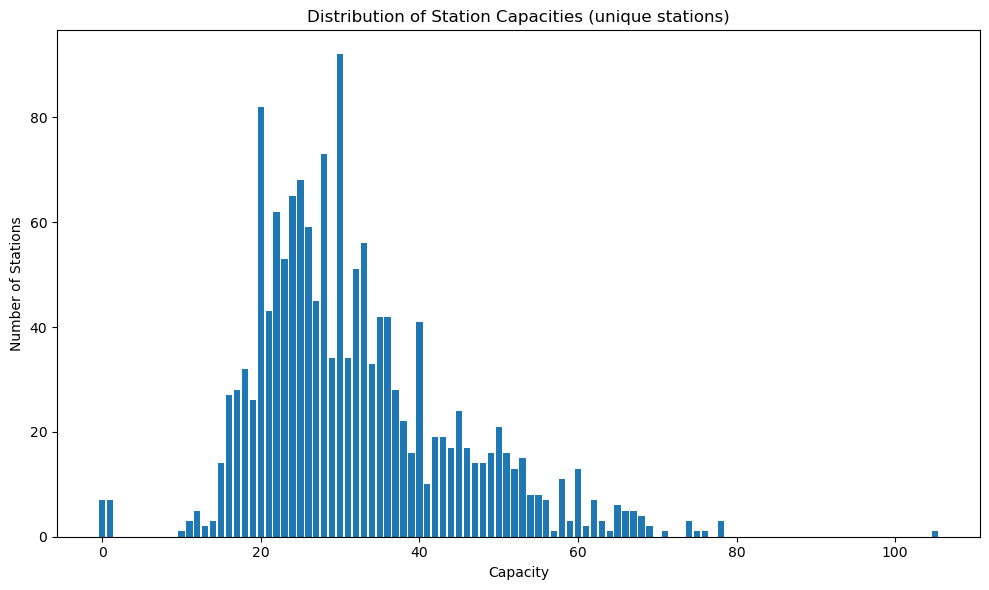

In [39]:
# Only one row per station_code to get unique capacities
station_capacity = (
    df.groupby("station_code")["capacity"]
      .max()
      .reset_index()
)

# Count how many stations have each capacity
capacity_counts = (
    station_capacity["capacity"]
    .value_counts()
    .sort_index()
    .reset_index()
)

capacity_counts.columns = ["capacity", "num_stations"]

print(f"Total stations: {station_capacity.shape[0]}")
print(f"Sum of num_stations:", capacity_counts["num_stations"].sum())
print(f"Stations with no valid capacity: ", (station_capacity.shape[0] - capacity_counts["num_stations"].sum()))


display(capacity_counts)


# Plot
plt.figure(figsize=(10,6))
plt.bar(capacity_counts["capacity"], capacity_counts["num_stations"])
plt.xlabel("Capacity")
plt.ylabel("Number of Stations")
plt.title("Distribution of Station Capacities (unique stations)")
plt.tight_layout()
plt.show()


# REMOVE THE ONES WITH VERY LOW CAPACITY NUMBER

In [40]:
bad_capacity_stations = station_capacity[
    station_capacity["capacity"] <= 1 # We choose 1 by looking at the histogram 
]["station_code"]

print("Stations to remove:", len(bad_capacity_stations))

Stations to remove: 14


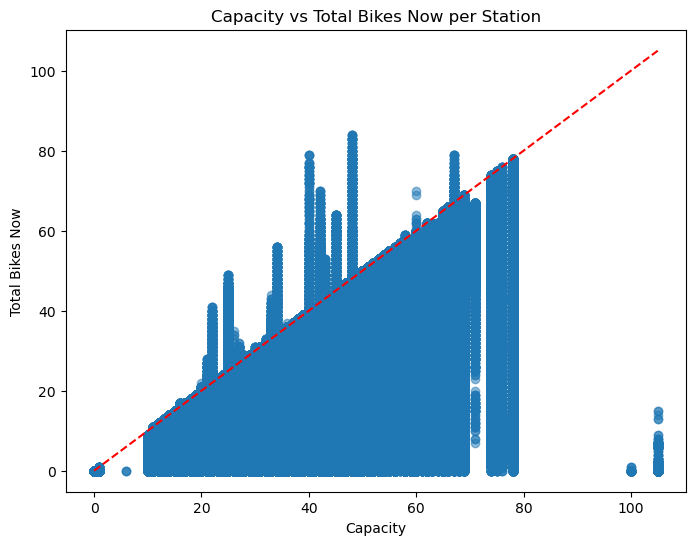

In [41]:
plt.figure(figsize=(8,6))
plt.scatter(df["capacity"], df["total_bikes_now"], alpha=0.5)
plt.plot([0, df["capacity"].max()], [0, df["capacity"].max()], color="red", linestyle="--")
plt.xlabel("Capacity")
plt.ylabel("Total Bikes Now")
plt.title("Capacity vs Total Bikes Now per Station")
plt.show()

# REMOVE BAD CAPACITY STATIONS

In [42]:
# ~ means not in pandas
df = df[~df["station_code"].isin(bad_capacity_stations)] # Removing whole stations
log_pipeline_step(df, "Drop Stations with Capacity < 2")
print_df(df)
df = df[df["capacity"] > 1] # Removing rows
log_pipeline_step(df, "Drop Rows with Capacity < 2")
print_df(df)

Dataframe analysis
-----------------------
Shape: 
rows:     6024073
features: 23
Dataframe size: 4930677918 bytes (4702.26 MB)
-----------------------
Percentage of rows removed: 0.76%
Percentage of stations removed: 0.88%
Percentage of real rows removed: 0.76%
Percentage of real stations removed: 0.88%
-----------------------


station_name          object
station_code           int64
ebike                 object
mechanical            object
latitude             float64
longitude            float64
duedate               object
total_bikes_now      float64
total_bikes_taken    float64
capacity             float64
is_renting            object
is_installed          object
commune_name          object
is_returning          object
postal_code           object
timestamp             object
weather_interval      object
temperature          float64
is_day               float64
wind_speed           float64
wind_direction       float64
weather_code         float64
source_file           object
dtype: object

-----------------------


,station_code,latitude,longitude,total_bikes_now,total_bikes_taken,capacity,temperature,is_day,wind_speed,wind_direction,weather_code
count,6.024073e+06,5.972435e+06,5.993435e+06,5.994098e+06,5.973098e+06,5.972435e+06,5.948589e+06,5.948589e+06,5.948589e+06,5.948589e+06,5.948589e+06
mean,1.890061e+04,4.885761e+01,2.348840e+00,1.255691e+01,1.854836e+01,3.206895e+01,1.208019e+01,3.969632e-01,9.490494e+00,1.935789e+02,1.517105e+01
std,1.239622e+04,3.250224e-02,2.735376e-01,1.105299e+01,1.234393e+01,1.238877e+01,5.192788e+01,7.510754e-01,4.263808e+00,6.609120e+01,2.632496e+01
min,0.000000e+00,4.874339e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-3.900000e+00,-7.000000e-01,0.000000e+00,4.000000e-01,0.000000e+00
25%,1.103000e+04,4.883657e+01,2.302526e+00,4.000000e+00,9.000000e+00,2.300000e+01,6.800000e+00,0.000000e+00,6.500000e+00,1.580000e+02,3.000000e+00
50%,1.700300e+04,4.885800e+01,2.344058e+00,1.000000e+01,1.700000e+01,3.000000e+01,9.200000e+00,0.000000e+00,9.300000e+00,1.830000e+02,3.000000e+00
75%,2.230200e+04,4.887940e+01,2.380221e+00,1.800000e+01,2.600000e+01,3.800000e+01,1.140000e+01,1.000000e+00,1.220000e+01,2.250000e+02,3.000000e+00
max,9.200800e+04,4.895757e+01,4.500000e+01,8.400000e+01,1.000000e+02,1.050000e+02,9.000000e+02,1.510000e+01,2.850000e+01,3.600000e+02,3.600000e+02


Dataframe analysis
-----------------------
Shape: 
rows:     5940155
features: 23
Dataframe size: 4872543624 bytes (4646.82 MB)
-----------------------
Percentage of rows removed: 2.14%
Percentage of stations removed: 5.80%
Percentage of real rows removed: 2.14%
Percentage of real stations removed: 5.80%
-----------------------


station_name          object
station_code           int64
ebike                 object
mechanical            object
latitude             float64
longitude            float64
duedate               object
total_bikes_now      float64
total_bikes_taken    float64
capacity             float64
is_renting            object
is_installed          object
commune_name          object
is_returning          object
postal_code           object
timestamp             object
weather_interval      object
temperature          float64
is_day               float64
wind_speed           float64
wind_direction       float64
weather_code         float64
source_file           object
dtype: object

-----------------------


,station_code,latitude,longitude,total_bikes_now,total_bikes_taken,capacity,temperature,is_day,wind_speed,wind_direction,weather_code
count,5.940155e+06,5.940155e+06,5.940155e+06,5.940155e+06,5.940155e+06,5.940155e+06,5.917866e+06,5.917866e+06,5.917866e+06,5.917866e+06,5.917866e+06
mean,1.901658e+04,4.885775e+01,2.341628e+00,1.264280e+01,1.864449e+01,3.223902e+01,1.165105e+01,3.920470e-01,9.494815e+00,1.936547e+02,1.508034e+01
std,1.230325e+04,3.223611e-02,5.853641e-02,1.104424e+01,1.230713e+01,1.220507e+01,4.813037e+01,7.155819e-01,4.260500e+00,6.599065e+01,2.595208e+01
min,1.001000e+03,4.874339e+01,2.165597e+00,0.000000e+00,0.000000e+00,6.000000e+00,-3.900000e+00,-7.000000e-01,0.000000e+00,4.000000e-01,0.000000e+00
25%,1.103900e+04,4.883659e+01,2.302426e+00,4.000000e+00,1.000000e+01,2.300000e+01,6.800000e+00,0.000000e+00,6.500000e+00,1.580000e+02,3.000000e+00
50%,1.700700e+04,4.885800e+01,2.343959e+00,1.000000e+01,1.700000e+01,3.000000e+01,9.200000e+00,0.000000e+00,9.300000e+00,1.830000e+02,3.000000e+00
75%,2.230300e+04,4.887940e+01,2.379654e+00,1.800000e+01,2.600000e+01,3.800000e+01,1.140000e+01,1.000000e+00,1.220000e+01,2.250000e+02,3.000000e+00
max,9.200800e+04,4.895757e+01,2.538242e+00,8.400000e+01,1.000000e+02,1.050000e+02,9.000000e+02,1.510000e+01,2.850000e+01,3.600000e+02,3.150000e+02


# RECALCULATE AND PLOT AFTER REMOVING

Total stations: 1493
Sum of num_stations: 1493
Stations with no valid capacity:  0


,capacity,num_stations
0,10.0,1
1,11.0,3
2,12.0,5
3,13.0,2
4,14.0,3
...,...,...
61,74.0,3
62,75.0,1
63,76.0,1
64,78.0,3


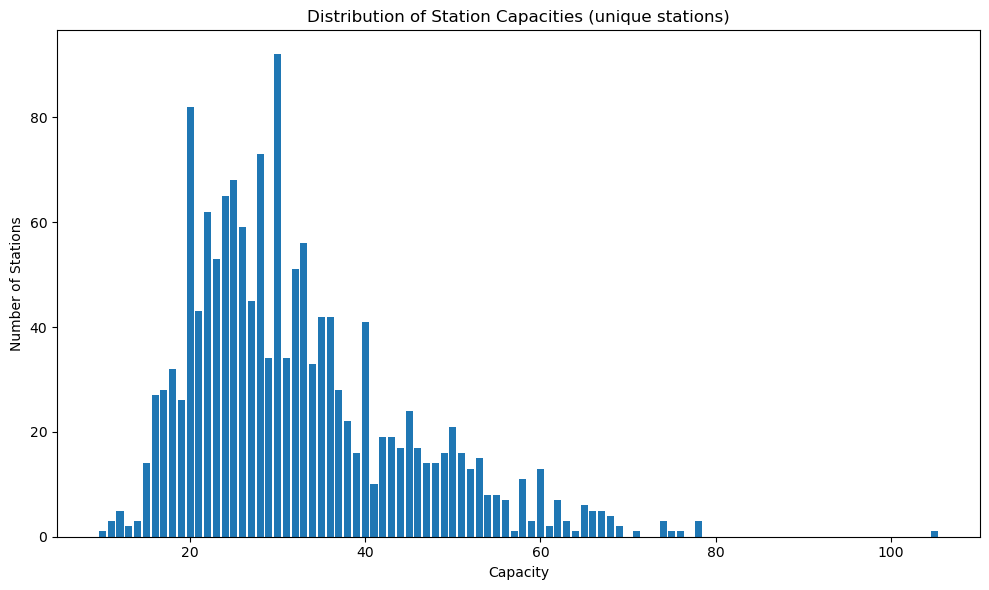

In [43]:
# Only one row per station_code to get unique capacities
station_capacity = (
    df.groupby("station_code")["capacity"]
      .max()
      .reset_index()
)

# Count how many stations have each capacity
capacity_counts = (
    station_capacity["capacity"]
    .value_counts()
    .sort_index()
    .reset_index()
)

capacity_counts.columns = ["capacity", "num_stations"]

print(f"Total stations: {station_capacity.shape[0]}")
print(f"Sum of num_stations:", capacity_counts["num_stations"].sum())
print(f"Stations with no valid capacity: ", (station_capacity.shape[0] - capacity_counts["num_stations"].sum()))


display(capacity_counts)


# Plot
plt.figure(figsize=(10,6))
plt.bar(capacity_counts["capacity"], capacity_counts["num_stations"])
plt.xlabel("Capacity")
plt.ylabel("Number of Stations")
plt.title("Distribution of Station Capacities (unique stations)")
plt.tight_layout()
plt.show()


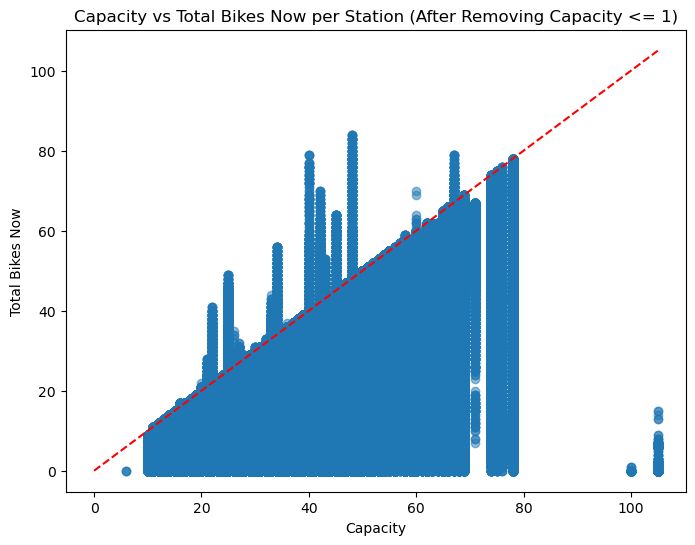

In [44]:
plt.figure(figsize=(8,6))
plt.scatter(df["capacity"], df["total_bikes_now"], alpha=0.5)
plt.plot([0, df["capacity"].max()], [0, df["capacity"].max()], color="red", linestyle="--")
plt.xlabel("Capacity")
plt.ylabel("Total Bikes Now")
plt.title("Capacity vs Total Bikes Now per Station (After Removing Capacity <= 1)")
plt.show()

# We do not see the dots at the 0 mark anymore, showing that it worked

# CHECK THE STATIONS WITH DOTS ABOVE THE RED LINE(THEY HAVE MORE BIKES THAN CAPACITY)

In [45]:
suspicious = df[df["total_bikes_now"] > df["capacity"]]
print(f"Number of suspicious stations: {suspicious.shape[0]}")
display(suspicious[["station_code", "capacity", "total_bikes_now", "total_bikes_taken"]])

Number of suspicious stations: 11788


,station_code,capacity,total_bikes_now,total_bikes_taken
683,15039,27.0,28.0,0.0
1439,42004,25.0,37.0,0.0
1488,21302,25.0,30.0,0.0
2171,15039,27.0,28.0,0.0
2933,42004,25.0,37.0,0.0
...,...,...,...,...
6068025,21302,25.0,39.0,1.0
6068031,12105,33.0,34.0,3.0
6068032,15056,22.0,23.0,2.0
6069521,21302,25.0,39.0,1.0


# CHECK THE PERCENTAGE OF IT TO NOT WRONGFULLY PURGE THE STATION WITH SMALL ERRORS

In [46]:
df["is_suspicious"] = df["total_bikes_now"] > df["capacity"]

station_stats = (
    df.groupby("station_code")
      .agg(
          total_rows=("station_code", "size"),
          suspicious_rows=("is_suspicious", "sum")
      )
)

station_stats["suspicious_ratio"] = (
    station_stats["suspicious_rows"] / station_stats["total_rows"]
)


station_stats_sorted = station_stats.sort_values("suspicious_ratio", ascending=False)
station_stats_nonzero = station_stats_sorted[station_stats_sorted["suspicious_ratio"] > 0] # Stations with at least 1 suspicious row

DROP_THRESHOLD = 0.10

stations_to_drop = station_stats_nonzero.loc[station_stats_sorted["suspicious_ratio"] >= DROP_THRESHOLD] # We will remove these stations completely
stations_to_rrow = station_stats_nonzero.loc[station_stats_sorted["suspicious_ratio"] < DROP_THRESHOLD] # We will only drop the rows

print("Stations to drop:", len(stations_to_drop))
print("Stations to remove_rows:", len(stations_to_rrow))

display(station_stats_nonzero)

Stations to drop: 9
Stations to remove_rows: 22


,total_rows,suspicious_rows,suspicious_ratio
station_code,,,
21302,3970,2319,0.584131
42004,4014,2165,0.539362
13123,4014,1713,0.426756
15056,2543,746,0.293354
12105,2579,569,0.220628
12127,3464,760,0.219400
21021,4014,743,0.185102
33019,3985,661,0.165872
15058,3991,601,0.150589


# SAVE VERY SUSPICIOUS TO A FILE

In [47]:
broken_station_path = f"{DELETED_STATIONS_FOLDER}/suspicious_stations.csv"
stats = df[df["station_code"].isin(station_stats_nonzero)].groupby("station_code")["total_bikes_now"].agg(
    ["mean", "std", "min", "max", "median"]
)
station_stats_full = station_stats_nonzero.join(stats)


with open(broken_station_path, "w", newline="", encoding="utf-8") as csvfile:
    writer = csv.writer(csvfile)
    # header
    writer.writerow(["station_code", "total_rows", "suspicious_rows", "suspicious_ratio",
        "mean_total_bikes_now", "std_total_bikes_now", "min_total_bikes_now",
        "max_total_bikes_now", "median_total_bikes_now"
    ])
    for station, row in station_stats_full.iterrows():
        writer.writerow([
            station,
            row["total_rows"],
            row["suspicious_rows"],
            row["suspicious_ratio"],
            row["mean"],
            row["std"],
            row["min"],
            row["max"],
            row["median"]
        ])

print(f"Suspicious stations saved: {len(station_stats_nonzero)}")
print(f"Saved: {broken_station_path}")

Suspicious stations saved: 31
Saved: ..\data\01_clean\deleted_stations/suspicious_stations.csv


In [48]:
broken_station_path = f"{DELETED_STATIONS_FOLDER}/bad_stations1.csv"
stats = df[df["station_code"].isin(station_stats_nonzero)].groupby("station_code")["total_bikes_now"].agg(
    ["mean", "std", "min", "max", "median"]
)
station_stats_full = station_stats_nonzero.join(stats)


with open(broken_station_path, "w", newline="", encoding="utf-8") as csvfile:
    writer = csv.writer(csvfile)
    # header
    writer.writerow(["station_code", "total_rows", "suspicious_rows", "suspicious_ratio",
        "mean_total_bikes_now", "std_total_bikes_now", "min_total_bikes_now",
        "max_total_bikes_now", "median_total_bikes_now"
    ])
    for station, row in station_stats_full.iterrows():
        writer.writerow([
            station,
            row["total_rows"],
            row["suspicious_rows"],
            row["suspicious_ratio"],
            row["mean"],
            row["std"],
            row["min"],
            row["max"],
            row["median"]
        ])

print(f"Broken stations saved: {len(stations_to_drop)}")
print(f"Saved: {broken_station_path}")

Broken stations saved: 9
Saved: ..\data\01_clean\deleted_stations/bad_stations1.csv


# DROP THE VERY SUSPICIOUS STATIONS

In [49]:
df = df[~df["station_code"].isin(stations_to_drop)]
log_pipeline_step(df, "Drop Stations Flagged as Very Suspicious")

# REMOVE THE SUSPICIOUS ROWS

In [50]:
df = df[~df['is_suspicious']]
log_pipeline_step(df, "Drop Suspicious Rows")

# REMOVE ROWS FOR STATIONS WITH MISTAKES

In [51]:
print_df(df)
mask = (df["total_bikes_now"] > df["capacity"])
df = df[~mask]
log_pipeline_step(df, "Enforce Bikes <= Capacity Constraint")
print_df(df)

Dataframe analysis
-----------------------
Shape: 
rows:     5928367
features: 24
Dataframe size: 4868706496 bytes (4643.16 MB)
-----------------------
Percentage of rows removed: 2.34%
Percentage of stations removed: 5.80%
Percentage of real rows removed: 2.34%
Percentage of real stations removed: 5.80%
-----------------------


station_name          object
station_code           int64
ebike                 object
mechanical            object
latitude             float64
longitude            float64
duedate               object
total_bikes_now      float64
total_bikes_taken    float64
capacity             float64
is_renting            object
is_installed          object
commune_name          object
is_returning          object
postal_code           object
timestamp             object
weather_interval      object
temperature          float64
is_day               float64
wind_speed           float64
wind_direction       float64
weather_code         float64
source_file           object
is_suspicious           bool
dtype: object

-----------------------


,station_code,latitude,longitude,total_bikes_now,total_bikes_taken,capacity,temperature,is_day,wind_speed,wind_direction,weather_code
count,5.928367e+06,5.928367e+06,5.928367e+06,5.928367e+06,5.928367e+06,5.928367e+06,5.906111e+06,5.906111e+06,5.906111e+06,5.906111e+06,5.906111e+06
mean,1.901193e+04,4.885779e+01,2.341637e+00,1.258639e+01,1.867689e+01,3.223835e+01,1.164998e+01,3.917188e-01,9.493962e+00,1.936520e+02,1.508431e+01
std,1.230442e+04,3.224014e-02,5.851955e-02,1.096870e+01,1.229718e+01,1.220926e+01,4.813067e+01,7.155320e-01,4.260804e+00,6.599409e+01,2.595433e+01
min,1.001000e+03,4.874339e+01,2.165597e+00,0.000000e+00,0.000000e+00,6.000000e+00,-3.900000e+00,-7.000000e-01,0.000000e+00,4.000000e-01,0.000000e+00
25%,1.103900e+04,4.883682e+01,2.302526e+00,4.000000e+00,1.000000e+01,2.300000e+01,6.800000e+00,0.000000e+00,6.500000e+00,1.580000e+02,3.000000e+00
50%,1.700700e+04,4.885804e+01,2.343959e+00,1.000000e+01,1.700000e+01,3.000000e+01,9.200000e+00,0.000000e+00,9.300000e+00,1.830000e+02,3.000000e+00
75%,2.230300e+04,4.887940e+01,2.379654e+00,1.800000e+01,2.600000e+01,3.800000e+01,1.140000e+01,1.000000e+00,1.220000e+01,2.250000e+02,3.000000e+00
max,9.200800e+04,4.895757e+01,2.538242e+00,7.800000e+01,1.000000e+02,1.050000e+02,9.000000e+02,1.510000e+01,2.850000e+01,3.600000e+02,3.150000e+02


Dataframe analysis
-----------------------
Shape: 
rows:     5928367
features: 24
Dataframe size: 4868706496 bytes (4643.16 MB)
-----------------------
Percentage of rows removed: 2.34%
Percentage of stations removed: 5.80%
Percentage of real rows removed: 2.34%
Percentage of real stations removed: 5.80%
-----------------------


station_name          object
station_code           int64
ebike                 object
mechanical            object
latitude             float64
longitude            float64
duedate               object
total_bikes_now      float64
total_bikes_taken    float64
capacity             float64
is_renting            object
is_installed          object
commune_name          object
is_returning          object
postal_code           object
timestamp             object
weather_interval      object
temperature          float64
is_day               float64
wind_speed           float64
wind_direction       float64
weather_code         float64
source_file           object
is_suspicious           bool
dtype: object

-----------------------


,station_code,latitude,longitude,total_bikes_now,total_bikes_taken,capacity,temperature,is_day,wind_speed,wind_direction,weather_code
count,5.928367e+06,5.928367e+06,5.928367e+06,5.928367e+06,5.928367e+06,5.928367e+06,5.906111e+06,5.906111e+06,5.906111e+06,5.906111e+06,5.906111e+06
mean,1.901193e+04,4.885779e+01,2.341637e+00,1.258639e+01,1.867689e+01,3.223835e+01,1.164998e+01,3.917188e-01,9.493962e+00,1.936520e+02,1.508431e+01
std,1.230442e+04,3.224014e-02,5.851955e-02,1.096870e+01,1.229718e+01,1.220926e+01,4.813067e+01,7.155320e-01,4.260804e+00,6.599409e+01,2.595433e+01
min,1.001000e+03,4.874339e+01,2.165597e+00,0.000000e+00,0.000000e+00,6.000000e+00,-3.900000e+00,-7.000000e-01,0.000000e+00,4.000000e-01,0.000000e+00
25%,1.103900e+04,4.883682e+01,2.302526e+00,4.000000e+00,1.000000e+01,2.300000e+01,6.800000e+00,0.000000e+00,6.500000e+00,1.580000e+02,3.000000e+00
50%,1.700700e+04,4.885804e+01,2.343959e+00,1.000000e+01,1.700000e+01,3.000000e+01,9.200000e+00,0.000000e+00,9.300000e+00,1.830000e+02,3.000000e+00
75%,2.230300e+04,4.887940e+01,2.379654e+00,1.800000e+01,2.600000e+01,3.800000e+01,1.140000e+01,1.000000e+00,1.220000e+01,2.250000e+02,3.000000e+00
max,9.200800e+04,4.895757e+01,2.538242e+00,7.800000e+01,1.000000e+02,1.050000e+02,9.000000e+02,1.510000e+01,2.850000e+01,3.600000e+02,3.150000e+02


In [52]:
TOTAL_REAL_ROWS_AT_START = df.shape[0]
TOTAL_REAL_STATIONS_AT_START = df["station_code"].nunique()
print(f"{TOTAL_REAL_ROWS_AT_START=}") # We will not change this anymore
print(f"{TOTAL_REAL_STATIONS_AT_START=}") # We will not change this anymore

TOTAL_REAL_ROWS_AT_START=5928367
TOTAL_REAL_STATIONS_AT_START=1493


# CHECK

In [53]:
print_df(df)
print_missing(df)

Dataframe analysis
-----------------------
Shape: 
rows:     5928367
features: 24
Dataframe size: 4868706496 bytes (4643.16 MB)
-----------------------
Percentage of rows removed: 2.34%
Percentage of stations removed: 5.80%
Percentage of real rows removed: 0.00%
Percentage of real stations removed: 0.00%
-----------------------


station_name          object
station_code           int64
ebike                 object
mechanical            object
latitude             float64
longitude            float64
duedate               object
total_bikes_now      float64
total_bikes_taken    float64
capacity             float64
is_renting            object
is_installed          object
commune_name          object
is_returning          object
postal_code           object
timestamp             object
weather_interval      object
temperature          float64
is_day               float64
wind_speed           float64
wind_direction       float64
weather_code         float64
source_file           object
is_suspicious           bool
dtype: object

-----------------------


,station_code,latitude,longitude,total_bikes_now,total_bikes_taken,capacity,temperature,is_day,wind_speed,wind_direction,weather_code
count,5.928367e+06,5.928367e+06,5.928367e+06,5.928367e+06,5.928367e+06,5.928367e+06,5.906111e+06,5.906111e+06,5.906111e+06,5.906111e+06,5.906111e+06
mean,1.901193e+04,4.885779e+01,2.341637e+00,1.258639e+01,1.867689e+01,3.223835e+01,1.164998e+01,3.917188e-01,9.493962e+00,1.936520e+02,1.508431e+01
std,1.230442e+04,3.224014e-02,5.851955e-02,1.096870e+01,1.229718e+01,1.220926e+01,4.813067e+01,7.155320e-01,4.260804e+00,6.599409e+01,2.595433e+01
min,1.001000e+03,4.874339e+01,2.165597e+00,0.000000e+00,0.000000e+00,6.000000e+00,-3.900000e+00,-7.000000e-01,0.000000e+00,4.000000e-01,0.000000e+00
25%,1.103900e+04,4.883682e+01,2.302526e+00,4.000000e+00,1.000000e+01,2.300000e+01,6.800000e+00,0.000000e+00,6.500000e+00,1.580000e+02,3.000000e+00
50%,1.700700e+04,4.885804e+01,2.343959e+00,1.000000e+01,1.700000e+01,3.000000e+01,9.200000e+00,0.000000e+00,9.300000e+00,1.830000e+02,3.000000e+00
75%,2.230300e+04,4.887940e+01,2.379654e+00,1.800000e+01,2.600000e+01,3.800000e+01,1.140000e+01,1.000000e+00,1.220000e+01,2.250000e+02,3.000000e+00
max,9.200800e+04,4.895757e+01,2.538242e+00,7.800000e+01,1.000000e+02,1.050000e+02,9.000000e+02,1.510000e+01,2.850000e+01,3.600000e+02,3.150000e+02


Missing diagnostics
-----------------------

NaN / Inf per column:


,nan,inf
is_day,22256,0
temperature,22256,0
weather_code,22256,0
weather_interval,22256,0
wind_direction,22256,0
wind_speed,22256,0
timestamp,20216,0
source_file,2040,0
capacity,0,0
commune_name,0,0


-----------------------


# DROP INVALID ROWS(DOESNT CONTAIN THE DATA FOR TOTAL_BIKES_NOW)

In [54]:
essential_data = [
    "station_name", 
    "station_code", 
    "postal_code", #
    "capacity", 
    "total_bikes_now", 
    "total_bikes_taken", 
    "timestamp"
]

df = df.dropna(subset=essential_data)
log_pipeline_step(df, "Drop Invalid Rows")

# RECHECK

In [55]:
print_missing(df)

Missing diagnostics
-----------------------

NaN / Inf per column:


,nan,inf
is_day,2040,0
source_file,2040,0
temperature,2040,0
weather_code,2040,0
weather_interval,2040,0
wind_direction,2040,0
wind_speed,2040,0
capacity,0,0
commune_name,0,0
duedate,0,0


-----------------------


# KEEPING THE USABLE COLUMNS

In [56]:
# Keep only useful columns
keep_cols = [
    "station_code",
    "latitude",
    "longitude",
    "capacity",
    "total_bikes_now",
    "total_bikes_taken",
    "timestamp",
    "temperature",
    "wind_speed",
    "wind_direction",
    "weather_code",
    "is_day",
]

df_cleaned = df[keep_cols].copy(deep=True)

print("Initial shape:", df_cleaned.shape)
print_df(df_cleaned)

Initial shape: (5908151, 12)
Dataframe analysis
-----------------------
Shape: 
rows:     5908151
features: 12
Dataframe size: 998765834 bytes (952.50 MB)
-----------------------
Percentage of rows removed: 2.67%
Percentage of stations removed: 5.80%
Percentage of real rows removed: 0.34%
Percentage of real stations removed: 0.00%
-----------------------


station_code           int64
latitude             float64
longitude            float64
capacity             float64
total_bikes_now      float64
total_bikes_taken    float64
timestamp             object
temperature          float64
wind_speed           float64
wind_direction       float64
weather_code         float64
is_day               float64
dtype: object

-----------------------


,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,temperature,wind_speed,wind_direction,weather_code,is_day
count,5.908151e+06,5.908151e+06,5.908151e+06,5.908151e+06,5.908151e+06,5.908151e+06,5.906111e+06,5.906111e+06,5.906111e+06,5.906111e+06,5.906111e+06
mean,1.898434e+04,4.885793e+01,2.341553e+00,3.225096e+01,1.260187e+01,1.867894e+01,1.164998e+01,9.493962e+00,1.936520e+02,1.508431e+01,3.917188e-01
std,1.228418e+04,3.202620e-02,5.850609e-02,1.220912e+01,1.096636e+01,1.229880e+01,4.813067e+01,4.260804e+00,6.599409e+01,2.595433e+01,7.155320e-01
min,1.001000e+03,4.874339e+01,2.165597e+00,1.000000e+01,0.000000e+00,0.000000e+00,-3.900000e+00,0.000000e+00,4.000000e-01,0.000000e+00,-7.000000e-01
25%,1.103800e+04,4.883683e+01,2.302426e+00,2.300000e+01,4.000000e+00,1.000000e+01,6.800000e+00,6.500000e+00,1.580000e+02,3.000000e+00,0.000000e+00
50%,1.700600e+04,4.885810e+01,2.343854e+00,3.000000e+01,1.000000e+01,1.700000e+01,9.200000e+00,9.300000e+00,1.830000e+02,3.000000e+00,0.000000e+00
75%,2.230100e+04,4.887941e+01,2.379330e+00,3.800000e+01,1.800000e+01,2.600000e+01,1.140000e+01,1.220000e+01,2.250000e+02,3.000000e+00,1.000000e+00
max,9.200800e+04,4.895757e+01,2.538242e+00,1.050000e+02,7.800000e+01,1.000000e+02,9.000000e+02,2.850000e+01,3.600000e+02,3.150000e+02,1.510000e+01


# WEATHER TIME HANDLING

In [57]:
df_cleaned["timestamp"] = pd.to_datetime(df_cleaned["timestamp"], errors="coerce")

# Drop rows without time
df_cleaned = df_cleaned.dropna(subset=["timestamp"])

# Time features
df_cleaned["hour"] = df_cleaned["timestamp"].dt.hour
df_cleaned["day_of_week"] = df_cleaned["timestamp"].dt.dayofweek
df_cleaned["is_weekend"] = (df_cleaned["day_of_week"] >= 5).astype(int)

# Cyclical encoding(to make hour continuous and not make it jump from 23 to 0)
df_cleaned["sin_hour"] = np.sin(2 * np.pi * df_cleaned["hour"] / 24)
df_cleaned["cos_hour"] = np.cos(2 * np.pi * df_cleaned["hour"] / 24)

In [58]:
print_df(df_cleaned)

Dataframe analysis
-----------------------
Shape: 
rows:     5888930
features: 17
Dataframe size: 800894480 bytes (763.79 MB)
-----------------------
Percentage of rows removed: 2.99%
Percentage of stations removed: 5.99%
Percentage of real rows removed: 0.67%
Percentage of real stations removed: 0.20%
-----------------------


station_code                  int64
latitude                    float64
longitude                   float64
capacity                    float64
total_bikes_now             float64
total_bikes_taken           float64
timestamp            datetime64[ns]
temperature                 float64
wind_speed                  float64
wind_direction              float64
weather_code                float64
is_day                      float64
hour                          int32
day_of_week                   int32
is_weekend                    int64
sin_hour                    float64
cos_hour                    float64
dtype: object

-----------------------


,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,timestamp,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour
count,5.888930e+06,5.888930e+06,5.888930e+06,5.888930e+06,5.888930e+06,5.888930e+06,5888930,5.888930e+06,5.888930e+06,5.888930e+06,5.888930e+06,5.888930e+06,5.888930e+06,5.888930e+06,5.888930e+06,5.888930e+06,5.888930e+06
mean,1.898420e+04,4.885793e+01,2.341553e+00,3.225101e+01,1.260299e+01,1.867792e+01,2025-11-28 15:27:52.684630528,9.058208e+00,9.520249e+00,1.941924e+02,1.464216e+01,3.643954e-01,1.142499e+01,2.985695e+00,2.843948e-01,1.086788e-02,3.064280e-03
min,1.001000e+03,4.875740e+01,2.165597e+00,1.000000e+01,0.000000e+00,0.000000e+00,2025-11-04 04:00:00,-3.900000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00
25%,1.103800e+04,4.883683e+01,2.302426e+00,2.300000e+01,4.000000e+00,1.000000e+01,2025-11-16 06:00:00,6.800000e+00,6.500000e+00,1.580000e+02,3.000000e+00,0.000000e+00,5.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01
50%,1.700600e+04,4.885810e+01,2.343854e+00,3.000000e+01,1.000000e+01,1.700000e+01,2025-11-28 12:15:00,9.200000e+00,9.300000e+00,1.830000e+02,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,6.123234e-17
75%,2.230100e+04,4.887941e+01,2.379330e+00,3.800000e+01,1.800000e+01,2.600000e+01,2025-12-11 01:30:00,1.140000e+01,1.220000e+01,2.250000e+02,3.000000e+00,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01
max,9.200800e+04,4.895757e+01,2.538242e+00,1.050000e+02,7.800000e+01,1.000000e+02,2025-12-23 12:15:00,1.950000e+01,2.850000e+01,3.600000e+02,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
std,1.228409e+04,3.202527e-02,5.850595e-02,1.220907e+01,1.096562e+01,1.229864e+01,NaN,3.768926e+00,4.239004e+00,6.532578e+01,2.447854e+01,4.812603e-01,6.927296e+00,2.003954e+00,4.511257e-01,7.073164e-01,7.068071e-01


# CHANGE FEATURE DATA TYPES FOR MEMORY OPTIMISATION

In [59]:
"""
df_cleaned = df_cleaned.astype({
    "station_code": "uint32",
    "latitude": "float64",
    "longitude": "float64",
    "capacity": "uint8",
    "total_bikes_now": "uint8",
    "total_bikes_taken": "uint8",
    "temperature": "float16",
    "wind_speed": "float16",
    "wind_direction": "float16",
    "weather_code": "uint8",
    "is_day": "uint8",
    "hour": "uint8",
    "day_of_week": "uint8",
    "is_weekend": "uint8",
    "sin_hour": "float32",
    "cos_hour": "float32"
})
"""
# We have abandoned the version above because we had problems in data due to overflow
df_cleaned = df_cleaned.astype({
    "station_code": "uint32",
    "latitude": "float64",
    "longitude": "float64",
    "capacity": "int64",
    "total_bikes_now": "int64",
    "total_bikes_taken": "int64",
    "temperature": "float64",
    "wind_speed": "float64",
    "wind_direction": "float64",
    "weather_code": "int64",
    "is_day": "int64",
    "hour": "int64",
    "day_of_week": "int64",
    "is_weekend": "int64",
    "sin_hour": "float64",
    "cos_hour": "float64"
})

print_df(df_cleaned)
df_cleaned.head()

Dataframe analysis
-----------------------
Shape: 
rows:     5888930
features: 17
Dataframe size: 824450200 bytes (786.26 MB)
-----------------------
Percentage of rows removed: 2.99%
Percentage of stations removed: 5.99%
Percentage of real rows removed: 0.67%
Percentage of real stations removed: 0.20%
-----------------------


station_code                 uint32
latitude                    float64
longitude                   float64
capacity                      int64
total_bikes_now               int64
total_bikes_taken             int64
timestamp            datetime64[ns]
temperature                 float64
wind_speed                  float64
wind_direction              float64
weather_code                  int64
is_day                        int64
hour                          int64
day_of_week                   int64
is_weekend                    int64
sin_hour                    float64
cos_hour                    float64
dtype: object

-----------------------


,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,timestamp,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour
count,5.888930e+06,5.888930e+06,5.888930e+06,5.888930e+06,5.888930e+06,5.888930e+06,5888930,5.888930e+06,5.888930e+06,5.888930e+06,5.888930e+06,5.888930e+06,5.888930e+06,5.888930e+06,5.888930e+06,5.888930e+06,5.888930e+06
mean,1.898420e+04,4.885793e+01,2.341553e+00,3.225101e+01,1.260299e+01,1.867792e+01,2025-11-28 15:27:52.684630528,9.058208e+00,9.520249e+00,1.941924e+02,1.464216e+01,3.643954e-01,1.142499e+01,2.985695e+00,2.843948e-01,1.086788e-02,3.064280e-03
min,1.001000e+03,4.875740e+01,2.165597e+00,1.000000e+01,0.000000e+00,0.000000e+00,2025-11-04 04:00:00,-3.900000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00
25%,1.103800e+04,4.883683e+01,2.302426e+00,2.300000e+01,4.000000e+00,1.000000e+01,2025-11-16 06:00:00,6.800000e+00,6.500000e+00,1.580000e+02,3.000000e+00,0.000000e+00,5.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01
50%,1.700600e+04,4.885810e+01,2.343854e+00,3.000000e+01,1.000000e+01,1.700000e+01,2025-11-28 12:15:00,9.200000e+00,9.300000e+00,1.830000e+02,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,6.123234e-17
75%,2.230100e+04,4.887941e+01,2.379330e+00,3.800000e+01,1.800000e+01,2.600000e+01,2025-12-11 01:30:00,1.140000e+01,1.220000e+01,2.250000e+02,3.000000e+00,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01
max,9.200800e+04,4.895757e+01,2.538242e+00,1.050000e+02,7.800000e+01,1.000000e+02,2025-12-23 12:15:00,1.950000e+01,2.850000e+01,3.600000e+02,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
std,1.228409e+04,3.202527e-02,5.850595e-02,1.220907e+01,1.096562e+01,1.229864e+01,NaN,3.768926e+00,4.239004e+00,6.532578e+01,2.447854e+01,4.812603e-01,6.927296e+00,2.003954e+00,4.511257e-01,7.073164e-01,7.068071e-01


,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,timestamp,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour
0,14111,48.837526,2.336035,25,2,22,2025-11-04 04:00:00,10.1,9.5,217.0,3,0,4,1,0,0.866025,0.5
1,32017,48.936269,2.358867,22,6,16,2025-11-04 04:00:00,10.1,9.5,217.0,3,0,4,1,0,0.866025,0.5
2,11104,48.855908,2.392571,20,2,18,2025-11-04 04:00:00,10.1,9.5,217.0,3,0,4,1,0,0.866025,0.5
3,5110,48.843893,2.351966,23,7,15,2025-11-04 04:00:00,10.1,9.5,217.0,3,0,4,1,0,0.866025,0.5
4,6108,48.847082,2.321375,17,4,11,2025-11-04 04:00:00,10.1,9.5,217.0,3,0,4,1,0,0.866025,0.5


# DETECTING THE DUPLICATE ROWS(MULTIPLE ROWS FOR THE SAME (STATION, TIMESTAMP) COUPLES)

In [60]:
dup_mask = df_cleaned.duplicated(
    subset=["station_code", "timestamp"],
    keep=False
)

print(f"Duplicate rows: {dup_mask.sum()}")

display(
    df_cleaned.loc[dup_mask]
    .groupby(["station_code", "timestamp"])
    .size()
    .rename("dup_count")
    .sort_values(ascending=False)
    .head(10)
)
del dup_mask

Duplicate rows: 19361


station_code  timestamp          
20203         2025-11-07 04:00:00    4
18139         2025-11-07 03:45:00    4
18137         2025-11-07 03:45:00    4
21506         2025-11-07 03:45:00    4
13046         2025-11-07 03:45:00    4
              2025-11-07 04:00:00    4
31202         2025-11-07 04:00:00    4
              2025-11-07 03:45:00    4
21506         2025-11-07 04:00:00    4
13047         2025-11-07 03:45:00    4
Name: dup_count, dtype: int64

# SET THE AGGREGATION RULES

In [61]:
agg_rules = {
    "latitude": "first",
    "longitude": "first",
    "capacity": "first",
    "total_bikes_now": "mean",
    "total_bikes_taken": "mean",
    "temperature": "mean",
    "wind_speed": "mean",
    "wind_direction": "mean",
    "weather_code": "first",
    "is_day": "first",
    "hour": "first",
    "day_of_week": "first",
    "is_weekend": "first",
    "sin_hour": "first",
    "cos_hour": "first",
}
# In the rows that have the same station_code and timestamp, these will be the rules to choose the value for the row that will be put there

# APPLY AGGREGATION RULES

In [62]:
before = df_cleaned.shape[0]

df_cleaned = (
    df_cleaned
    .groupby(["station_code", "timestamp"], as_index=False)
    .agg(agg_rules)
)
log_pipeline_step(df_cleaned, "Drop Duplicate Rows")

after = df_cleaned.shape[0]

print(f"Rows before: {before}")
print(f"Rows after : {after}")
print(f"Duplicates removed: {before - after}")
# We have a different number that is from what we got above. This is because we remove the extras here.

Rows before: 5888930
Rows after : 5876315
Duplicates removed: 12615


# CHECK IF THERE ARE STILL DUPLICATES

In [63]:
assert not df_cleaned.duplicated(
    ["station_code", "timestamp"]
).any()
# No error means no duplicates

# CHECK IF THERE ARE ANOMALIES IN CAPACITY SOMEHOW

In [64]:
capacity_stats = (
    df_cleaned
    .groupby('station_code')['capacity']
    .agg(['min', 'max', 'median'])
    .reset_index()
)

# Keep only stations where min != max
anomalous_stations = capacity_stats[capacity_stats['min'] != capacity_stats['max']]

print("Stations with differing min and max capacities:")
print(anomalous_stations)
# The anomalous stations keeps the stations where the capacity is not a fixed value. 
# This means there are stations where they have upgraded the slots.

Stations with differing min and max capacities:
      station_code  min  max  median
29            2004   16   17    17.0
326          10152   19   44    44.0
398          12006   30   41    41.0
464          12507  100  105   105.0
618          15033   30   45    45.0
656          15108   22   36    36.0
882          19026   17   30    30.0
904          19111   39   40    40.0
910          19121   21   35    21.0
991          20204   35   36    36.0
1161         23202   17   28    27.0


# HISTOGRAM OF ROWS

In [65]:
df_counts = df_cleaned["station_code"].value_counts().reset_index()
df_counts.columns = ["station_code", "count"]
print(df_counts)
# Row count for each station

      station_code  count
0            42303   3989
1            41208   3989
2            32004   3989
3            32020   3989
4            32019   3989
...            ...    ...
1485         43202    423
1486         43201    346
1487         18208     99
1488         10152     25
1489         35010      3

[1490 rows x 2 columns]


count
3         1
25        1
99        1
346       1
423       1
       ... 
3985    124
3986    176
3987     88
3988     29
3989     27
Name: count, Length: 64, dtype: int64


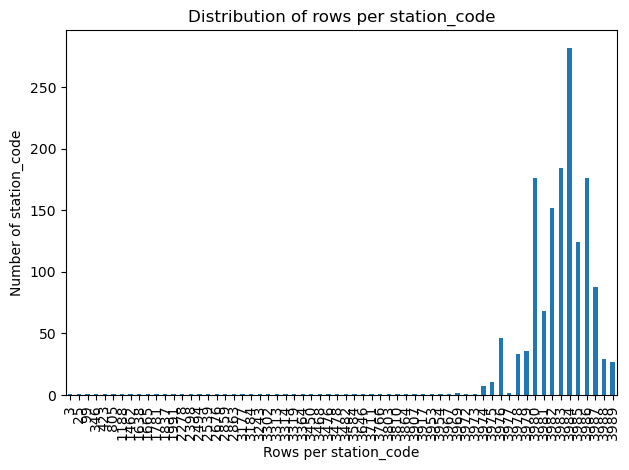

In [66]:
counts = df_cleaned["station_code"].value_counts() # index=station_code, value=#rows
count_distribution = counts.value_counts().sort_index()
print(f"{count_distribution}")
count_distribution.plot(kind="bar")
plt.xlabel("Rows per station_code")
plt.ylabel("Number of station_code")
plt.title("Distribution of rows per station_code")
plt.tight_layout()
plt.show()
# How many stations have X rows...

# MAKE THE MAP BEFORE DELETING STATIONS

In [67]:
def save_unique_stations_map_html(
    df,
    out_html="idf_stations",
    station_col="station_code",
    lat_col="latitude",
    lon_col="longitude",
    radius=0.01,               
    color="red",
    fill_opacity=0.8,
    zoom_start=10,
    tiles="CartoDB positronNoLabels",
):
    # Keep only needed cols, drop missing coords
    d = df[[station_col, lat_col, lon_col]].dropna(subset=[lat_col, lon_col])

    # To not redo the same station over and over
    d = d.drop_duplicates(subset=[station_col], keep="first")

    # Ensure numeric
    d[lat_col] = d[lat_col].astype(float)
    d[lon_col] = d[lon_col].astype(float)

    # Center map
    center_lat = float(d[lat_col].mean())
    center_lon = float(d[lon_col].mean())

    # Minimal basemap
    m = folium.Map(location=[center_lat, center_lon], zoom_start=zoom_start, tiles=tiles)

    # Plot points
    for code, la, lo in d.itertuples(index=False):
        folium.CircleMarker(
            location=[la, lo],
            radius=radius,
            color=color,
            fill=True,
            fill_color=color,
            fill_opacity=fill_opacity,
            tooltip=str(code),
        ).add_to(m)
    
    out_path = f"{MAP_FOLDER}/{out_html}.html"
    m.save(out_path)

    return out_path, len(d)


In [68]:
html_path, n = save_unique_stations_map_html(df_cleaned, out_html="idf_stations_before", radius=0.01)
print("Saved:", html_path, "| stations mapped:", n)

Saved: ..\data\05_visualization\maps/idf_stations_before.html | stations mapped: 1490


# DETECT BROKEN STATIONS

In [69]:
MIN_ROWS = counts.quantile(0.05)   # up to ~5% of the stations at the bottom can be deleted

cols = ["total_bikes_now", "total_bikes_taken"]

station_stats = (
    df_cleaned
    .groupby("station_code")[cols]
    .agg(["count", "mean", "std"])
)

# To get the stations with very low row count, ~5% of the stations
# This ignores the NaN values for total_bikes_now, which will not happen anyways as we have checked it does not have NaN values
rule_few_rows = station_stats[("total_bikes_now", "count")] < MIN_ROWS

# Rules for total_bikes_now
rule_now_bad = (
    station_stats[("total_bikes_now", "std")].isna() |
    (station_stats[("total_bikes_now", "std")] < 0.1) | # Get the ones where there are no big change
    (station_stats[("total_bikes_now", "mean")] < 0.5) # Get the ones where it is almost always 0
)

# Rules for total_bikes_taken
rule_taken_bad = (
    station_stats[("total_bikes_taken", "std")].isna() |
    (station_stats[("total_bikes_taken", "std")] < 0.1) | # Get the ones where there are no big change
    (station_stats[("total_bikes_taken", "mean")] < 0.5) # Get the ones where it is almost always 0
)

bad_stations = station_stats[
    rule_few_rows | rule_now_bad | rule_taken_bad # Union them
].index

print(f"{rule_few_rows.sum()} stations removed by row count")
print(f"{rule_now_bad.sum()} stations removed by bikes_now stats")
print(f"{rule_taken_bad.sum()} stations removed by bikes_taken stats")
print(f"Stations to remove: {len(bad_stations)}")

good_stations = df_cleaned["station_code"].unique()
good_stations = [s for s in good_stations if s not in bad_stations]

print(f"Stations to keep: {len(good_stations)}")
# Here we can see how many stations are affected by specific rules.
# We will need to remove them to keep the data integrity.


67 stations removed by row count
11 stations removed by bikes_now stats
9 stations removed by bikes_taken stats
Stations to remove: 73
Stations to keep: 1417


# REMOVE THE BROKEN STATIONS

In [70]:
print_df(df_cleaned)

df_kept = df_cleaned[df_cleaned["station_code"].isin(good_stations)].copy()
log_pipeline_step(df_kept, "Drop Broken Stations")

print_df(df_kept)

Dataframe analysis
-----------------------
Shape: 
rows:     5876315
features: 17
Dataframe size: 775673712 bytes (739.74 MB)
-----------------------
Percentage of rows removed: 3.20%
Percentage of stations removed: 5.99%
Percentage of real rows removed: 0.88%
Percentage of real stations removed: 0.20%
-----------------------


station_code                 uint32
timestamp            datetime64[ns]
latitude                    float64
longitude                   float64
capacity                      int64
total_bikes_now             float64
total_bikes_taken           float64
temperature                 float64
wind_speed                  float64
wind_direction              float64
weather_code                  int64
is_day                        int64
hour                          int64
day_of_week                   int64
is_weekend                    int64
sin_hour                    float64
cos_hour                    float64
dtype: object

-----------------------


,station_code,timestamp,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour
count,5.876315e+06,5876315,5.876315e+06,5.876315e+06,5.876315e+06,5.876315e+06,5.876315e+06,5.876315e+06,5.876315e+06,5.876315e+06,5.876315e+06,5.876315e+06,5.876315e+06,5.876315e+06,5.876315e+06,5.876315e+06,5.876315e+06
mean,1.898361e+04,2025-11-28 16:31:32.903478528,4.885793e+01,2.341552e+00,3.225114e+01,1.260145e+01,1.867938e+01,9.055039e+00,9.527163e+00,1.942765e+02,1.466849e+01,3.651019e-01,1.144023e+01,2.984339e+00,2.850053e-01,9.294048e-03,1.950592e-03
min,1.001000e+03,2025-11-04 04:00:00,4.875740e+01,2.165597e+00,1.000000e+01,0.000000e+00,0.000000e+00,-3.900000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00
25%,1.103800e+04,2025-11-16 07:45:00,4.883683e+01,2.302426e+00,2.300000e+01,4.000000e+00,1.000000e+01,6.800000e+00,6.500000e+00,1.590000e+02,3.000000e+00,0.000000e+00,5.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01
50%,1.700600e+04,2025-11-28 13:15:00,4.885810e+01,2.343854e+00,3.000000e+01,1.000000e+01,1.700000e+01,9.200000e+00,9.300000e+00,1.840000e+02,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,6.123234e-17
75%,2.230100e+04,2025-12-11 02:00:00,4.887941e+01,2.379330e+00,3.800000e+01,1.800000e+01,2.600000e+01,1.140000e+01,1.230000e+01,2.250000e+02,3.000000e+00,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01
max,9.200800e+04,2025-12-23 12:15:00,4.895757e+01,2.538242e+00,1.050000e+02,7.800000e+01,1.000000e+02,1.950000e+01,2.850000e+01,3.600000e+02,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
std,1.228394e+04,NaN,3.202472e-02,5.850472e-02,1.220938e+01,1.096603e+01,1.229813e+01,3.772199e+00,4.240491e+00,6.536190e+01,2.449817e+01,4.814588e-01,6.925571e+00,2.005390e+00,4.514170e-01,7.070968e-01,7.070531e-01


Dataframe analysis
-----------------------
Shape: 
rows:     5644165
features: 17
Dataframe size: 790183100 bytes (753.58 MB)
-----------------------
Percentage of rows removed: 7.02%
Percentage of stations removed: 10.60%
Percentage of real rows removed: 4.79%
Percentage of real stations removed: 5.09%
-----------------------


station_code                 uint32
timestamp            datetime64[ns]
latitude                    float64
longitude                   float64
capacity                      int64
total_bikes_now             float64
total_bikes_taken           float64
temperature                 float64
wind_speed                  float64
wind_direction              float64
weather_code                  int64
is_day                        int64
hour                          int64
day_of_week                   int64
is_weekend                    int64
sin_hour                    float64
cos_hour                    float64
dtype: object

-----------------------


,station_code,timestamp,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour
count,5.644165e+06,5644165,5.644165e+06,5.644165e+06,5.644165e+06,5.644165e+06,5.644165e+06,5.644165e+06,5.644165e+06,5.644165e+06,5.644165e+06,5.644165e+06,5.644165e+06,5.644165e+06,5.644165e+06,5.644165e+06,5.644165e+06
mean,1.907989e+04,2025-11-28 16:01:00.532638976,4.885773e+01,2.340879e+00,3.228864e+01,1.272242e+01,1.859091e+01,9.059655e+00,9.511304e+00,1.942892e+02,1.465793e+01,3.654339e-01,1.144043e+01,2.983475e+00,2.847695e-01,9.246948e-03,1.444543e-03
min,1.001000e+03,2025-11-04 04:00:00,4.876462e+01,2.165597e+00,1.000000e+01,0.000000e+00,0.000000e+00,-3.900000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00
25%,1.103700e+04,2025-11-16 07:00:00,4.883650e+01,2.302116e+00,2.300000e+01,4.000000e+00,1.000000e+01,6.800000e+00,6.500000e+00,1.590000e+02,3.000000e+00,0.000000e+00,5.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01
50%,1.700400e+04,2025-11-28 12:45:00,4.885800e+01,2.343101e+00,3.000000e+01,1.000000e+01,1.700000e+01,9.200000e+00,9.300000e+00,1.840000e+02,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,6.123234e-17
75%,2.240200e+04,2025-12-11 01:30:00,4.887951e+01,2.378623e+00,3.800000e+01,1.800000e+01,2.600000e+01,1.140000e+01,1.220000e+01,2.250000e+02,3.000000e+00,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01
max,9.200800e+04,2025-12-23 12:15:00,4.895757e+01,2.538242e+00,7.800000e+01,7.800000e+01,7.800000e+01,1.950000e+01,2.850000e+01,3.600000e+02,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
std,1.240567e+04,NaN,3.218336e-02,5.840450e-02,1.212563e+01,1.097453e+01,1.215729e+01,3.772468e+00,4.233961e+00,6.534607e+01,2.449184e+01,4.815517e-01,6.923657e+00,2.005048e+00,4.513046e-01,7.070225e-01,7.071292e-01


# BUILD THE FULL BUT EMPTY(FOR NOW) DATAFRAME

In [71]:
# Min/max timestamp per station
station_ranges = (
    df_kept
    .groupby("station_code")["timestamp"]
    .agg(["min", "max"])
)

dfs = []

for station, (start, end) in station_ranges.iterrows():
    full_index = pd.date_range(start, end, freq="15min")

    full_df = pd.DataFrame({
        "station_code": station,
        "timestamp": full_index
    })

    merged = full_df.merge(
        df_kept[df_kept["station_code"] == station],
        on=["station_code", "timestamp"],
        how="left"
    )

    dfs.append(merged)

df_full = pd.concat(dfs, ignore_index=True).copy()
log_pipeline_step(df_full, "Build Full Dataframe")

print(f"Rows after full timeline: {len(df_full)}")
print(f"Added rows: {len(df_full) - len(df_kept)}")
# We build the dataset by adding the missing timestamps in the dataset
# We can see that there were a lot of timestamps missing.

Rows after full timeline: 6713672
Added rows: 1069507


# DETECT MISSING ROWS

In [72]:
missing_rows = df_full[df_full["total_bikes_now"].isna()]

missing_per_station = (
    missing_rows
    .groupby("station_code")
    .size()
    .sort_values(ascending=False)
)

print("Stations with most missing rows:")
display(missing_per_station.head(10))

Stations with most missing rows:


station_code
20029    762
20011    762
20137    762
12122    762
20140    762
12123    762
12125    762
20009    762
12128    762
12129    762
dtype: int64

# FILL STATIC COLUMNS

In [73]:
static_cols = ["latitude", "longitude"] # Will be the same for its own station

df_full[static_cols] = (
    df_full
    .groupby("station_code")[static_cols]
    .transform("first")
)

# Capacity needs its own treatment as it changes over time
df_full["capacity"] = (
    df_full
    .groupby("station_code")["capacity"]
    .transform(lambda x: x.ffill().bfill()) # Forward-fill then back-fill
)

# We fill the static data first.

# FILL WEATHER DATA WITH FORWARD-BACKWARD FILL

In [74]:
weather_cols = [
    "temperature",
    "wind_speed",
    "wind_direction",
    "weather_code",
    "is_day",
]

for col in weather_cols:
    df_full[col] = (
        df_full
        .groupby("station_code")[col]
        .transform(lambda g: g.ffill().bfill())
    )

# We fill the weather data with this technique to make the data seamless
# Because the mean takes the whole data into account, it might just jump inbetween data, 
# like from 3 to 8 to 5 because the mean of the data is 8. 

# FILL BIKE DATA WITH INTERPOLATION

In [75]:
bike_cols = ["total_bikes_now", "total_bikes_taken"]

# Interpolate per station using timestamp as index
def interpolate_bikes(group):
    group = group.set_index("timestamp")  # DatetimeIndex required
    # This makes a linear fill.
    # For example if we have 3, _, 5 then it will fill _ with 4.
    group[bike_cols] = group[bike_cols].interpolate(method="time")
    return group.reset_index() # To keep the dataframe same as before

In [76]:
# Sort first
df_full = df_full.sort_values(["station_code", "timestamp"])

df_full = df_full.groupby("station_code").apply(interpolate_bikes).reset_index(drop=True).copy()

# Fill edges
df_full[bike_cols] = df_full[bike_cols].fillna(method="ffill").fillna(method="bfill")
# We first fill the data with a linear way first using interpolate(method="time"), then we fill the edges with forward-backward fill.

C:\Users\emirh\AppData\Local\Temp\ipykernel_185480\650788558.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_full = df_full.groupby("station_code").apply(interpolate_bikes).reset_index(drop=True).copy()
C:\Users\emirh\AppData\Local\Temp\ipykernel_185480\650788558.py:7: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_full[bike_cols] = df_full[bike_cols].fillna(method="ffill").fillna(method="bfill")


# FILL THE REST OF THE TIME DATA

In [77]:
df_full["hour"] = df_full["timestamp"].dt.hour.astype("int64")
df_full["day_of_week"] = df_full["timestamp"].dt.dayofweek.astype("int64")
df_full["is_weekend"] = (df_full["day_of_week"] >= 5).astype("int64")
df_full["sin_hour"] = np.sin(2 * np.pi * df_full["hour"] / 24).astype("float64")
df_full["cos_hour"] = np.cos(2 * np.pi * df_full["hour"] / 24).astype("float64")
# To fill them, we use the same way we have made them at the first place.
# We add the astype to keep the data type same.

# CHECK

In [78]:
print("Remaining NaNs per column:")
print(df_full.isna().sum())

print("Final rows:", len(df_full))
print("Final stations:", df_full["station_code"].nunique())

Remaining NaNs per column:
timestamp            0
station_code         0
latitude             0
longitude            0
capacity             0
total_bikes_now      0
total_bikes_taken    0
temperature          0
wind_speed           0
wind_direction       0
weather_code         0
is_day               0
hour                 0
day_of_week          0
is_weekend           0
sin_hour             0
cos_hour             0
dtype: int64
Final rows: 6713672
Final stations: 1417


# MAKE THE MAP AFTER DELETING/REFILLING

In [79]:
html_path, n = save_unique_stations_map_html(df_full, radius=0.01, out_html="idf_stations_removed_refilled")
print("Saved:", html_path, "| stations mapped:", n)
# This way we can see if the broken stations are at around the same place in the map.

Saved: ..\data\05_visualization\maps/idf_stations_removed_refilled.html | stations mapped: 1417


# SAVE THE BROKEN STATIONS IN A FILE

In [80]:
broken_station_path = f"{DELETED_STATIONS_FOLDER}/broken_stations2.csv"
stats = df_cleaned[df_cleaned["station_code"].isin(bad_stations)].groupby("station_code")["total_bikes_now"].agg(
    ["mean", "std", "min", "max", "median"]
)

with open(broken_station_path, "w", newline="", encoding="utf-8") as csvfile:
    writer = csv.writer(csvfile)
    # header
    writer.writerow(["station_code", "mean_total_bikes_now", "std_total_bikes_now", "min_total_bikes_now",
        "max_total_bikes_now", "median_total_bikes_now"])
    for station, row in stats.iterrows():
        writer.writerow([
            station,
            row["mean"],
            row["std"],
            row["min"],
            row["max"],
            row["median"]
        ])

print(f"Broken stations saved: {len(bad_stations)}")
print(f"Saved: {broken_station_path}")
# If we see NaN values, it means it always had that value for every row.

Broken stations saved: 73
Saved: ..\data\01_clean\deleted_stations/broken_stations2.csv


# CHECK

In [81]:
print(df_full.isna().sum().sort_values(ascending=False))
# Check if we have any NaN values

timestamp            0
wind_direction       0
sin_hour             0
is_weekend           0
day_of_week          0
hour                 0
is_day               0
weather_code         0
wind_speed           0
station_code         0
temperature          0
total_bikes_taken    0
total_bikes_now      0
capacity             0
longitude            0
latitude             0
cos_hour             0
dtype: int64


# DETAILS

In [82]:
print_df(df_full)

Dataframe analysis
-----------------------
Shape: 
rows:     6713672
features: 17
Dataframe size: 913059524 bytes (870.76 MB)
-----------------------
Percentage of rows removed: -10.60%
Percentage of stations removed: 10.60%
Percentage of real rows removed: -13.25%
Percentage of real stations removed: 5.09%
-----------------------


timestamp            datetime64[ns]
station_code                  int64
latitude                    float64
longitude                   float64
capacity                    float64
total_bikes_now             float64
total_bikes_taken           float64
temperature                 float64
wind_speed                  float64
wind_direction              float64
weather_code                float64
is_day                      float64
hour                          int64
day_of_week                   int64
is_weekend                    int64
sin_hour                    float64
cos_hour                    float64
dtype: object

-----------------------


,timestamp,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour
count,6713672,6.713672e+06,6.713672e+06,6.713672e+06,6.713672e+06,6.713672e+06,6.713672e+06,6.713672e+06,6.713672e+06,6.713672e+06,6.713672e+06,6.713672e+06,6.713672e+06,6.713672e+06,6.713672e+06,6.713672e+06,6.713672e+06
mean,2025-11-28 20:07:53.490692352,1.907977e+04,4.885773e+01,2.340881e+00,3.228884e+01,1.271876e+01,1.859506e+01,9.066004e+00,9.505749e+00,1.945041e+02,1.468609e+01,3.657919e-01,1.147328e+01,2.985670e+00,2.836671e-01,5.165546e-03,-2.571228e-03
min,2025-11-04 04:00:00,1.001000e+03,4.876462e+01,2.165597e+00,1.000000e+01,0.000000e+00,0.000000e+00,-3.900000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00
25%,2025-11-16 12:00:00,1.103700e+04,4.883650e+01,2.302116e+00,2.300000e+01,4.000000e+00,1.000000e+01,6.800000e+00,6.500000e+00,1.590000e+02,3.000000e+00,0.000000e+00,6.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01
50%,2025-11-28 20:15:00,1.700400e+04,4.885800e+01,2.343101e+00,3.000000e+01,1.000000e+01,1.700000e+01,9.200000e+00,9.300000e+00,1.840000e+02,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,-1.836970e-16
75%,2025-12-11 04:15:00,2.240200e+04,4.887951e+01,2.378623e+00,3.800000e+01,1.800000e+01,2.550000e+01,1.140000e+01,1.220000e+01,2.250000e+02,3.000000e+00,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01
max,2025-12-23 12:15:00,9.200800e+04,4.895757e+01,2.538242e+00,7.800000e+01,7.800000e+01,7.800000e+01,1.950000e+01,2.850000e+01,3.600000e+02,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
std,NaN,1.240546e+04,3.218145e-02,5.840658e-02,1.212561e+01,1.096758e+01,1.214734e+01,3.760196e+00,4.238307e+00,6.506985e+01,2.453183e+01,4.816516e-01,6.907651e+00,1.999949e+00,4.507772e-01,7.076428e-01,7.065469e-01


# ADD BIKE LAG

In [83]:
df_full = df_full.sort_values(["station_code", "timestamp"])
df_full["total_bikes_lag1"] = df_full.groupby("station_code")["total_bikes_now"].shift(1)
df_full["total_bikes_lag2"] = df_full.groupby("station_code")["total_bikes_now"].shift(2)
df_full = df_full.dropna(subset=["total_bikes_lag1", "total_bikes_lag2"]).copy()
# We just put the value from 1 or 2 rows before(after sorting and grouping of course).
# This will make the values for the first and second row NaN, but this is not a significant number for the dataset.
# Thats why we can just drop it.

# SPLIT THE DATASET

In [84]:
df_full["split"] = None
for station_code, df_station in df_full.groupby("station_code"):
    n = len(df_station)
    train_end = int(0.7 * n)
    val_end = int(0.85 * n)

    # Get original indices
    idx = df_station.index
    df_full.loc[idx[:train_end], "split"] = 0 # "train"
    df_full.loc[idx[train_end:val_end], "split"] = 1 # "val"
    df_full.loc[idx[val_end:], "split"] = 2 # "test"

# Here we split the dataset. 
# By marking them like that, it is impossible to accidently use the test values.
# Also the sorting by station_code and timestamp part is important,
# this gives a chronological split between the rows for each station and not just randomize it.
# Randomizing it might have made biases towards specific stations.

# LAST CHECK

In [85]:
print_df(df_full)
print_missing(df_full)

Dataframe analysis
-----------------------
Shape: 
rows:     6710838
features: 20
Dataframe size: 1585856896 bytes (1512.39 MB)
-----------------------
Percentage of rows removed: -10.55%
Percentage of stations removed: 10.60%
Percentage of real rows removed: -13.20%
Percentage of real stations removed: 5.09%
-----------------------


timestamp            datetime64[ns]
station_code                  int64
latitude                    float64
longitude                   float64
capacity                    float64
total_bikes_now             float64
total_bikes_taken           float64
temperature                 float64
wind_speed                  float64
wind_direction              float64
weather_code                float64
is_day                      float64
hour                          int64
day_of_week                   int64
is_weekend                    int64
sin_hour                    float64
cos_hour                    float64
total_bikes_lag1            float64
total_bikes_lag2            float64
split                        object
dtype: object

-----------------------


,timestamp,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour,total_bikes_lag1,total_bikes_lag2
count,6710838,6.710838e+06,6.710838e+06,6.710838e+06,6.710838e+06,6.710838e+06,6.710838e+06,6.710838e+06,6.710838e+06,6.710838e+06,6.710838e+06,6.710838e+06,6.710838e+06,6.710838e+06,6.710838e+06,6.710838e+06,6.710838e+06,6.710838e+06,6.710838e+06
mean,2025-11-28 20:22:53.490685440,1.907977e+04,4.885773e+01,2.340881e+00,3.228885e+01,1.271832e+01,1.859539e+01,9.065579e+00,9.505767e+00,1.944947e+02,1.469103e+01,3.659464e-01,1.147643e+01,2.986508e+00,2.837869e-01,4.802003e-03,-2.783465e-03,1.271847e+01,1.271861e+01
min,2025-11-04 04:30:00,1.001000e+03,4.876462e+01,2.165597e+00,1.000000e+01,0.000000e+00,0.000000e+00,-3.900000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00,0.000000e+00,0.000000e+00
25%,2025-11-16 12:30:00,1.103700e+04,4.883650e+01,2.302116e+00,2.300000e+01,4.000000e+00,1.000000e+01,6.800000e+00,6.500000e+00,1.590000e+02,3.000000e+00,0.000000e+00,6.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01,4.000000e+00,4.000000e+00
50%,2025-11-28 20:30:00,1.700400e+04,4.885800e+01,2.343101e+00,3.000000e+01,1.000000e+01,1.700000e+01,9.200000e+00,9.300000e+00,1.840000e+02,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,-1.836970e-16,1.000000e+01,1.000000e+01
75%,2025-12-11 04:30:00,2.240200e+04,4.887951e+01,2.378623e+00,3.800000e+01,1.800000e+01,2.550000e+01,1.140000e+01,1.220000e+01,2.250000e+02,3.000000e+00,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01,1.800000e+01,1.800000e+01
max,2025-12-23 12:15:00,9.200800e+04,4.895757e+01,2.538242e+00,7.800000e+01,7.800000e+01,7.800000e+01,1.950000e+01,2.850000e+01,3.600000e+02,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,7.800000e+01,7.800000e+01
std,NaN,1.240546e+04,3.218145e-02,5.840658e-02,1.212561e+01,1.096771e+01,1.214705e+01,3.760931e+00,4.239199e+00,6.508198e+01,2.453584e+01,4.816946e-01,6.907401e+00,1.999955e+00,4.508347e-01,7.075710e-01,7.066206e-01,1.096763e+01,1.096756e+01


Missing diagnostics
-----------------------

NaN / Inf per column:


,nan,inf
capacity,0,0
cos_hour,0,0
day_of_week,0,0
hour,0,0
is_day,0,0
is_weekend,0,0
latitude,0,0
longitude,0,0
sin_hour,0,0
split,0,0


-----------------------


# SAVE ONLY THE STATIONS AND THEIR COORDINATES

In [86]:
station_info_cols = [
    "station_code",
    "station_name",
    "latitude",
    "longitude",
    "commune_name",
    "postal_code",
    "capacity"
]

# Columns to take from df (all station info columns except capacity)
static_cols = [c for c in station_info_cols if c not in ["station_code", "capacity"]]

# Take metadata from df
df_meta = df[["station_code"] + static_cols].drop_duplicates(subset=["station_code"], keep="first")

# Take latest capacity per station from df_full
df_capacity = df_full.groupby("station_code")["capacity"].last().reset_index()

# Merge metadata with latest capacity, only for stations in df_full
df_station_info = df_meta.merge(df_capacity, on="station_code", how="inner")

# Reorder columns according to station_info_cols
existing_cols = [c for c in station_info_cols if c in df_station_info.columns]
df_station_info = df_station_info[existing_cols]

# Sort it for easier use in menu later
df_station_info = df_station_info.sort_values(["commune_name", "station_name"]).reset_index(drop=True)

# Save CSV
df_station_info.to_csv(f"{COORDINATES_FOLDER}/station_info.csv", index=False)
print(f"Station info saved to: {COORDINATES_FOLDER}/station_info.csv")

# We need the station_info_cols to make a menu in our program(to use the models later in real time).
# Capacity is for a fallback case, in case we cannot get velib data in our program.

Station info saved to: ..\data\02_features\station_coordinates/station_info.csv


# LAST HEAD

In [87]:
display(df_full.head(10))
log_pipeline_step(df_full, "Final Dataframe")

,timestamp,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour,total_bikes_lag1,total_bikes_lag2,split
2,2025-11-04 04:30:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.0,8.0,207.0,3.0,0.0,4,1,0,0.866025,5.000000e-01,2.0,2.0,0
3,2025-11-04 04:45:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.1,8.2,203.0,3.0,0.0,4,1,0,0.866025,5.000000e-01,2.0,2.0,0
4,2025-11-04 05:00:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.1,8.2,203.0,3.0,0.0,5,1,0,0.965926,2.588190e-01,2.0,2.0,0
5,2025-11-04 05:15:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.1,8.1,201.0,3.0,0.0,5,1,0,0.965926,2.588190e-01,2.0,2.0,0
6,2025-11-04 05:30:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.1,8.4,200.0,3.0,0.0,5,1,0,0.965926,2.588190e-01,2.0,2.0,0
7,2025-11-04 05:45:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.1,8.7,197.0,3.0,0.0,5,1,0,0.965926,2.588190e-01,2.0,2.0,0
8,2025-11-04 06:00:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.2,8.7,197.0,2.0,0.0,6,1,0,1.000000,6.123234e-17,2.0,2.0,0
9,2025-11-04 06:15:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.2,8.7,197.0,2.0,1.0,6,1,0,1.000000,6.123234e-17,2.0,2.0,0
10,2025-11-04 06:30:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.2,8.7,197.0,2.0,1.0,6,1,0,1.000000,6.123234e-17,2.0,2.0,0
11,2025-11-04 06:45:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.3,8.6,202.0,2.0,1.0,6,1,0,1.000000,6.123234e-17,2.0,2.0,0


# SAVE THE PIPELINE LOGS

In [88]:
pipeline_stats_df = pd.DataFrame(pipeline_stats)

pipeline_stats_df.to_csv(
    PIPELINE_STATS_FOLDER / "pipeline_stats.csv",
    index=False
)

print(f"Saved: {PIPELINE_STATS_FOLDER}/pipeline_stats.csv")

Saved: ..\data\06_statistics\pipeline/pipeline_stats.csv


# SAVE THE FINAL CLEAN DATASET

In [89]:
df_full.to_csv(f"{DATASET_OUTPUT_FOLDER}/{FINAL_CSV_FILE_NAME}.csv", index=False)
print(f"Clean dataset saved: {FINAL_CSV_FILE_NAME}.csv")

Clean dataset saved: final_clean_split_data.csv
